# เริ่มต้นสำรวจข้อมูล — ก่อนเทรนโมเดล

**อย่าข้ามสมุดเล่มนี้ไปเทรนเลย** สาเหตุอันดับหนึ่งที่โมเดลพยากรณ์ออกมาแปลก ๆ
ไม่ใช่การเลือกอัลกอริทึมผิด แต่เป็นข้อมูลที่ขาดหายหรือเพี้ยนโดยที่ไม่มีใครเปิดดูก่อน

ลำดับที่ควรทำ: ดูว่ามีข้อมูลกี่วัน → ขาดช่วงไหน → ค่าสมเหตุสมผลไหม → แล้วค่อยเทรน

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

DB = os.environ.get("DATABASE_URL", "postgresql://wx:wx@wx-db:5432/wx")
engine = create_engine(DB.replace("postgresql://", "postgresql+psycopg2://"))
print("ต่อฐานข้อมูลได้แล้ว")

ต่อฐานข้อมูลได้แล้ว


## 1. คลังข้อมูลมีอะไรอยู่บ้าง

ดูก่อนว่าแต่ละสถานีมีค่าอะไร กี่แถว ตั้งแต่เมื่อไรถึงเมื่อไร

In [2]:
pd.read_sql("""
    select s.name as สถานี, o.measure as ค่าที่วัด, count(*) as จำนวน,
           min(o.at) as ตั้งแต่, max(o.at) as ถึง
      from obs o join station s on s.id = o.station
     group by 1, 2 order by 1, 3 desc
""", engine)

,สถานี,ค่าที่วัด,จำนวน,ตั้งแต่,ถึง
0,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,pres_msl_hpa,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
1,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,dew_c,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
2,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,pres_sfc_hpa,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
3,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,rh,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
4,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,gust_ms,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
5,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,rain_mm,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
6,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,cloud_pct,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
7,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,rad_wm2,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
8,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,wind_ms,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00
9,Open-Meteo ที่พิกัดฟาร์มกำแพงเพชร,temp_c,9756,2025-07-26 00:00:00+00:00,2026-09-05 11:00:00+00:00


## 2. ข้อมูลขาดช่วงตรงไหนบ้าง

`เทรนโมเดลในเล้าได้` คือตัวเลขที่สำคัญที่สุด — จำนวนชั่วโมงที่**เทรนได้จริง**
เพราะต้องมีทั้งค่าในเล้าและค่าจากแบบจำลองโลกพร้อมกันในแถวเดียว

In [3]:
cov = pd.read_sql("select * from v_coverage order by วันที่", engine)
print(f"มีข้อมูล {len(cov)} วัน")
print(f"เทรนโมเดลในเล้าได้  {cov['เทรนโมเดลในเล้าได้'].sum():,} ชั่วโมง")
print(f"เทรนโมเดลนอกเล้าได้ {cov['เทรนโมเดลนอกเล้าได้'].sum():,} ชั่วโมง")
cov.tail(14)

มีข้อมูล 407 วัน
เทรนโมเดลในเล้าได้  228 ชั่วโมง
เทรนโมเดลนอกเล้าได้ 22 ชั่วโมง


,วันที่,ชม_ในเล้า,ชม_เสาฟาร์ม,ชม_openmeteo,เทรนโมเดลในเล้าได้,เทรนโมเดลนอกเล้าได้,อุณหภูมิเฉลี่ยในเล้า,อุณหภูมิเฉลี่ยข้างนอก
393,2026-08-23,0,0,24,0,0,NaN,27.0
394,2026-08-24,4,0,24,4,0,27.8,28.6
395,2026-08-25,22,0,24,22,0,27.2,28.2
396,2026-08-26,19,0,24,19,0,27.2,27.7
397,2026-08-27,18,0,24,18,0,26.6,27.8
398,2026-08-28,0,0,24,0,0,NaN,27.5
399,2026-08-29,0,0,24,0,0,NaN,28.0
400,2026-08-30,11,0,24,11,0,26.9,27.1
401,2026-08-31,19,0,24,19,0,26.8,26.6
402,2026-09-01,15,0,24,15,0,26.7,27.3


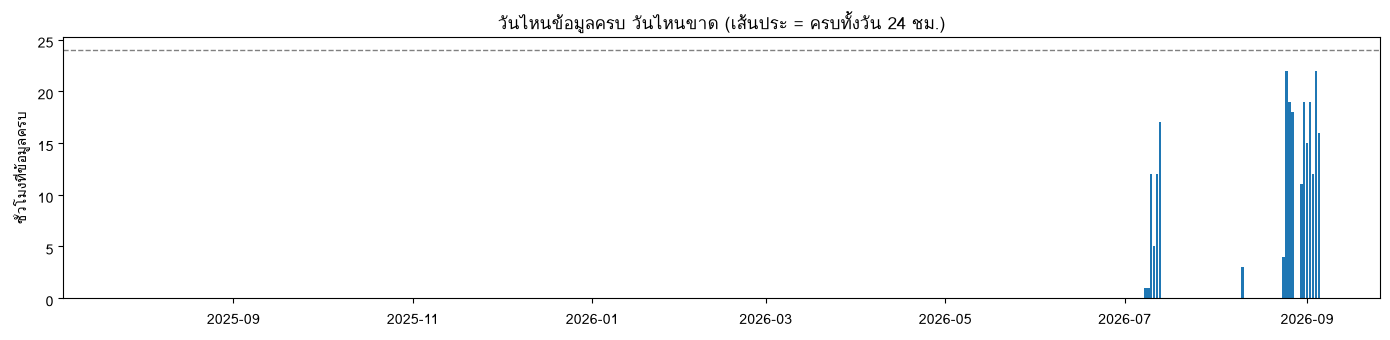

In [4]:
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(cov["วันที่"], cov["เทรนโมเดลในเล้าได้"], width=0.9)
ax.axhline(24, ls="--", lw=1, color="gray")
ax.set_ylabel("ชั่วโมงที่ข้อมูลครบ")
ax.set_title("วันไหนข้อมูลครบ วันไหนขาด (เส้นประ = ครบทั้งวัน 24 ชม.)")
plt.tight_layout(); plt.show()

## 3. ค่าที่เก็บมาสมเหตุสมผลไหม

ดู `min` กับ `max` เป็นหลัก ตัวเลขที่เป็นไปไม่ได้จะโผล่ตรงนี้ทันที
เช่น อุณหภูมิ 0 °C ในเล้าหมู หรือความชื้น 0 % ซึ่งแปลว่าเซนเซอร์ไม่ได้วัด ไม่ใช่ค่าจริง

In [5]:
df = pd.read_sql("select * from v_feature_1h order by at", engine,
                 parse_dates=["at"]).set_index("at")
cols = [c for c in ["barn_temp_c", "barn_rh", "barn_thi", "mast_temp_c", "mast_rh",
                    "wx_temp_c", "wx_rh", "wx_pres_msl_hpa", "wx_wind_ms", "wx_rad_wm2"]
        if c in df.columns]
df[cols].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)

,count,mean,std,min,50%,max
barn_temp_c,229.0,26.80,1.22,23.59,26.76,30.64
barn_rh,229.0,86.56,6.09,68.55,87.55,99.10
barn_thi,229.0,78.52,1.56,73.74,78.48,82.34
mast_temp_c,23.0,31.99,4.06,26.70,30.60,38.10
mast_rh,23.0,67.18,14.06,46.30,66.04,91.00
wx_temp_c,9756.0,27.08,3.57,14.10,26.90,38.00
wx_rh,9756.0,78.12,15.80,28.00,81.00,100.00
wx_pres_msl_hpa,9756.0,1009.15,3.68,999.80,1008.60,1021.60
wx_wind_ms,9756.0,1.51,0.87,0.00,1.39,7.61
wx_rad_wm2,9756.0,214.43,287.52,0.00,13.00,968.00


## 4. ในเล้ากับข้างนอกต่างกันแค่ไหน

เส้นพวกนี้คือหัวใจของงาน — ถ้าในเล้าเดินตามข้างนอกเป๊ะ โมเดลก็แทบไม่ต้องเรียนรู้อะไร
แต่ถ้าต่างกันมากและต่างไม่คงที่ นั่นคือสิ่งที่โมเดลมีหน้าที่อธิบาย

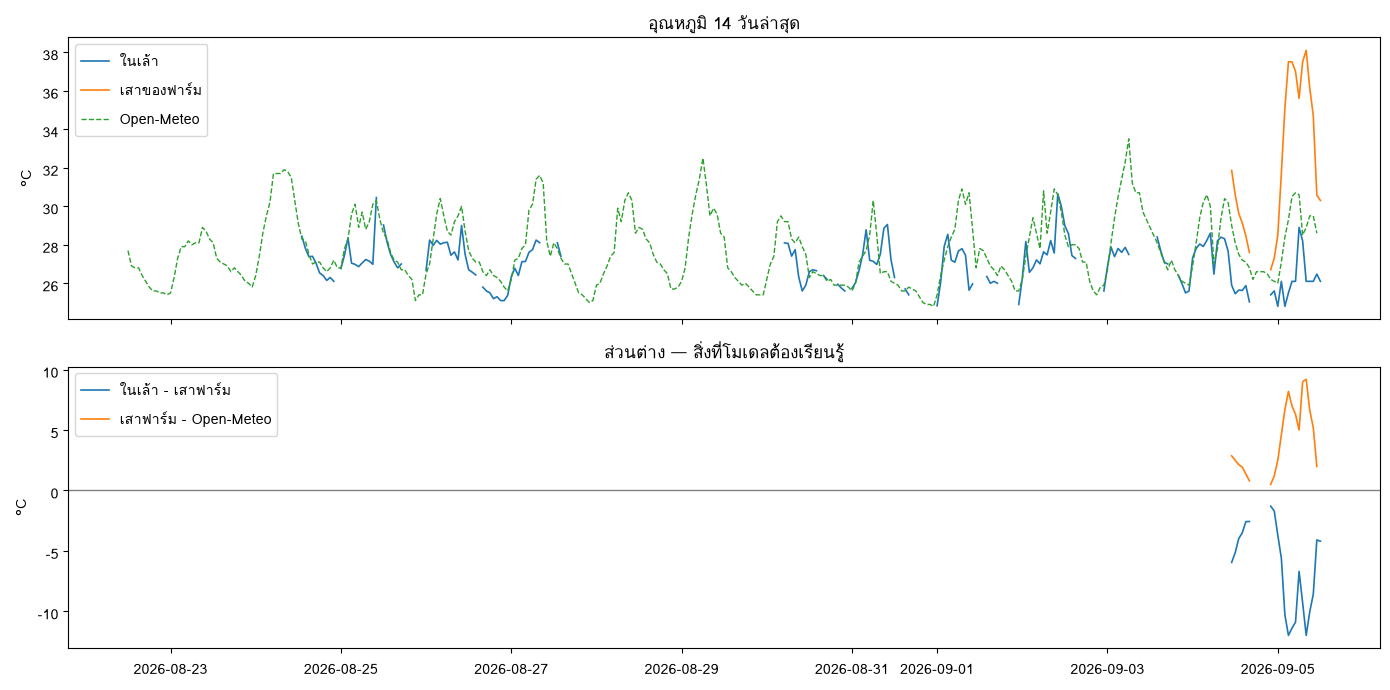

In [6]:
# pandas 3 เอา df.last() ออกไปแล้ว — ตัดช่วงด้วยการเทียบเวลาตรง ๆ แทน
recent = df[df.index >= df.index.max() - pd.Timedelta(days=14)]

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax[0].plot(recent.index, recent["barn_temp_c"], lw=1.2, label="ในเล้า")
ax[0].plot(recent.index, recent["mast_temp_c"], lw=1.2, label="เสาของฟาร์ม")
ax[0].plot(recent.index, recent["wx_temp_c"], lw=1.0, ls="--", label="Open-Meteo")
ax[0].set_ylabel("°C"); ax[0].legend(); ax[0].set_title("อุณหภูมิ 14 วันล่าสุด")

ax[1].plot(recent.index, recent["barn_minus_mast_c"], lw=1.2, label="ในเล้า - เสาฟาร์ม")
ax[1].plot(recent.index, recent["mast_minus_wx_c"], lw=1.2, label="เสาฟาร์ม - Open-Meteo")
ax[1].axhline(0, lw=1, color="gray")
ax[1].set_ylabel("°C"); ax[1].legend(); ax[1].set_title("ส่วนต่าง — สิ่งที่โมเดลต้องเรียนรู้")
plt.tight_layout(); plt.show()

## 5. ค่าไหนช่วยทำนายได้บ้าง

ดูความสัมพันธ์กับสิ่งที่จะทำนาย **ล่วงหน้า 6 ชั่วโมง** ไม่ใช่กับค่าปัจจุบัน
ความสัมพันธ์กับค่าปัจจุบันสูงเป็นเรื่องธรรมดา และไม่ได้บอกเลยว่าทำนายได้ไหม

In [7]:
target = df["barn_temp_c"].shift(-6)
num = df.select_dtypes("number")
corr = num.corrwith(target).dropna().sort_values(key=abs, ascending=False)
corr.head(20).to_frame("ความสัมพันธ์กับอุณหภูมิในเล้าอีก 6 ชม.").round(3)

/opt/conda/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/conda/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,ความสัมพันธ์กับอุณหภูมิในเล้าอีก 6 ชม.
hour_sin,0.450
hour_th,-0.314
hour_cos,-0.300
mast_minus_wx_c,0.288
barn_airflow_ms,-0.280
doy_sin,-0.238
doy,0.230
doy_cos,0.214
barn_rh,-0.208
mast_rh,-0.206


## 6. ต่อไปทำอะไร

รันโมเดลตั้งต้นในเทอร์มินัลของ JupyterLab (File → New → Terminal)

```bash
cd ~/work
python baseline.py --target barn_temp_c    # อุณหภูมิในเล้า
python baseline.py --target barn_thi       # ดัชนีความเครียดร้อน
python baseline.py --target mast_temp_c    # อุณหภูมิข้างนอกที่ฟาร์ม
python baseline.py --target wx_temp_c      # ทดสอบว่าท่อทั้งเส้นทำงาน (มีข้อมูลเยอะแล้ว)
```

ดูคอลัมน์ **ดีขึ้น** เป็นหลัก ถ้าติดลบแปลว่าโมเดลยังแพ้การทายว่า "เท่าเดิม"
ซึ่งเป็นเรื่องปกติมากตอนข้อมูลยังน้อย — ให้ตัวเก็บข้อมูลเดินต่อไปอีกสักพักแล้วลองใหม่